# 🔬 Procesamiento de Imágenes con IA — Clase 8: Operaciones de Filtrado y Frecuencia

**Politécnico Malvinas Argentinas** | Tecnicatura en Cs de Datos e IA | 2026
**Materia:** Procesamiento de Imágenes con IA
**Tipo:** Clase Práctica — Laboratorio de Demostración (Clase 8, Semana 4)
**Tema:** Filtros Espaciales · Detección de Bordes · Transformada de Fourier


---
> **¿Cómo usar este notebook?**
> Ejecutá cada celda en orden con `Shift + Enter`.
> Las celdas marcadas con `# TODO:` son las que tenés que completar vos.
> Las celdas de **Demo** las ejecuta el/la docente y las podés reusar como referencia.

## 🎯 Objetivos de Aprendizaje

| # | Objetivo | Nivel Bloom |
|---|----------|-------------|
| 1 | **Aplicar** filtros de suavizado (promedio, gaussiano, mediana) y comparar sus efectos | Aplicar |
| 2 | **Implementar** detección de bordes con gradiente, Sobel y Canny paso a paso | Aplicar |
| 3 | **Analizar** la relación entre el tamaño del kernel y el grado de suavizado | Analizar |
| 4 | **Comparar** el comportamiento de los filtros ante ruido sal y pimienta vs. ruido gaussiano | Evaluar |
| 5 | **Calcular** la FFT de una imagen y visualizar su espectro de magnitud | Aplicar |
| 6 | **Construir** filtros en el dominio de la frecuencia (pasa-bajos, pasa-altos) | Crear |
| 7 | **Evaluar** qué técnica es más apropiada para cada tarea de preprocesamiento | Evaluar |

---
## ⚙️ Paso 0 — Setup del Entorno

Instalamos dependencias y descargamos imágenes de prueba.

In [2]:
# ── Instalación (solo primera vez en Colab) ──────────────────────
%pip install opencv-python-headless matplotlib numpy scipy -q

# ── Imports ──────────────────────────────────────────────────────
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import ndimage
import urllib.request
import os

# ── Configuración de visualización ───────────────────────────────
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 11,
    'axes.titleweight': 'bold',
    'image.cmap': 'gray'
})

print("✅ Todo importado correctamente")
print(f"   OpenCV: {cv2.__version__}")
print(f"   NumPy:  {np.__version__}")

You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
✅ Todo importado correctamente
   OpenCV: 5.0.0
   NumPy:  2.0.2


ℹ️  Ya existe: lena.png

Imagen cargada: 512×512 px (escala de grises)


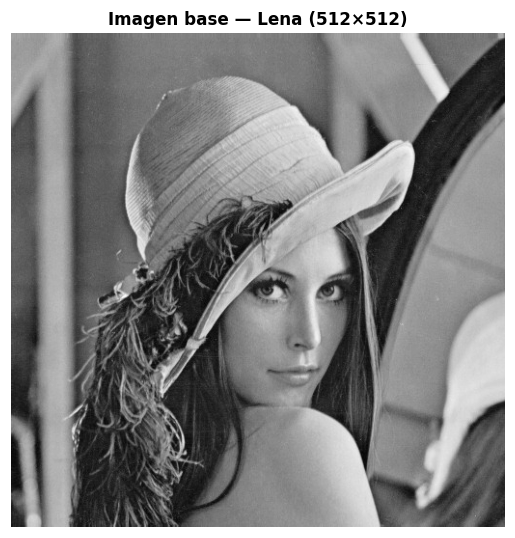

In [3]:
# ── Descarga de imágenes de prueba ───────────────────────────────
# Usamos imágenes estándar de visión computacional

def download_image(url, filename):
    """Descarga una imagen si no existe."""
    if not os.path.exists(filename):
        try:
            urllib.request.urlretrieve(url, filename)
            print(f"✅ Descargada: {filename}")
        except Exception as e:
            print(f"⚠️  Error al descargar {filename} desde {url}: {e}")
            return None # Retorna None si falla la descarga
    else:
        print(f"ℹ️  Ya existe: {filename}")
    return cv2.imread(filename)

# Imagen con textura y bordes definidos (Lena — clásica de procesamiento de imágenes)
url_lena   = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
# Imagen con ruido para testear filtros
url_coins  = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/coins.png"
# Imagen de paisaje
url_camera = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/astronaut.jpg"

img_color = download_image(url_lena, "lena.png")

if img_color is None:
    # Fallback: crear imagen sintética
    print("⚠️  No se pudo descargar. Usando imagen sintética.")
    img_color = np.zeros((256, 256, 3), dtype=np.uint8)
    cv2.rectangle(img_color, (50, 50), (200, 200), (200, 100, 50), -1)
    cv2.circle(img_color, (128, 128), 60, (50, 200, 150), -1)
    cv2.line(img_color, (0, 0), (255, 255), (255, 255, 0), 2)

img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)
print(f"\nImagen cargada: {img_gray.shape[1]}×{img_gray.shape[0]} px (escala de grises)")

# Mostrar imagen original
plt.figure(figsize=(5, 5))
plt.imshow(img_gray, cmap='gray')
plt.title("Imagen base — Lena (512×512)")
plt.axis('off')
plt.tight_layout()
plt.show()

---
## 🔷 Sección 1 — Filtros de Suavizado

### Teoría rápida
| Filtro | Operación | Característica | Cuándo usar |
|--------|-----------|----------------|-------------|
| Promedio (box) | Media de vecinos | Rápido, borra bordes | Prototipado rápido |
| Gaussiano | Media ponderada (σ) | Preserva mejor la estructura | Antes de Canny / Sobel |
| Mediana | Valor central ordenado | Elimina sal y pimienta | Ruido impulsivo |

### 🎬 Demo 1.1 — Comparación de filtros de suavizado

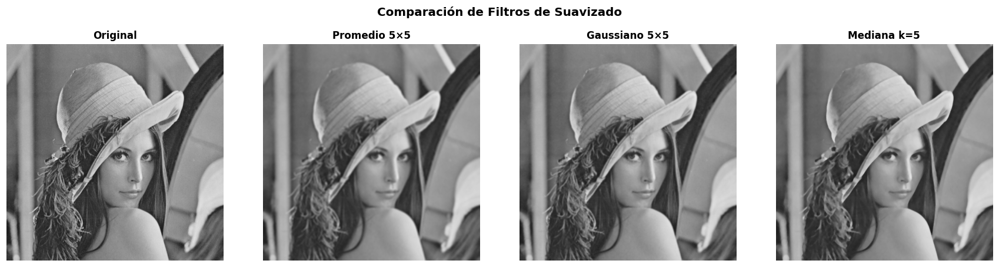

Promedio     → cambio promedio por píxel: 4.90
Gaussiano    → cambio promedio por píxel: 3.44
Mediana      → cambio promedio por píxel: 3.73


In [4]:
# ══════════════════════════════════════════════════════════════════
# DEMO 1.1: Los tres filtros con el mismo kernel 5×5
# ══════════════════════════════════════════════════════════════════

blur_avg    = cv2.blur(img_gray, (5, 5))
blur_gauss  = cv2.GaussianBlur(img_gray, (5, 5), 0)
blur_median = cv2.medianBlur(img_gray, 5)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
titulos = ["Original", "Promedio 5×5", "Gaussiano 5×5", "Mediana k=5"]
imgs    = [img_gray, blur_avg, blur_gauss, blur_median]

for ax, img, t in zip(axes, imgs, titulos):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')

plt.suptitle("Comparación de Filtros de Suavizado", fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Calcular diferencias con la original
for nombre, filtrado in [("Promedio", blur_avg), ("Gaussiano", blur_gauss), ("Mediana", blur_median)]:
    diff = np.abs(img_gray.astype(float) - filtrado.astype(float))
    print(f"{nombre:12s} → cambio promedio por píxel: {diff.mean():.2f}")

### 🎬 Demo 1.2 — Efecto del tamaño del kernel (σ-sweep)

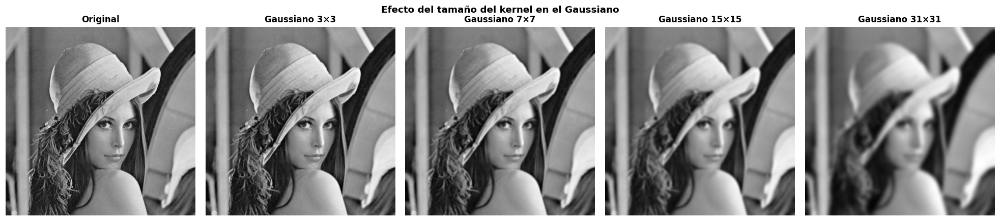

💡 Observá cómo aumenta el desenfoque con el ksize.
   Los bordes se vuelven cada vez más borrosos — eso afecta la detección posterior.


In [5]:
# ══════════════════════════════════════════════════════════════════
# DEMO 1.2: Gaussiano con distintos ksize
# ══════════════════════════════════════════════════════════════════

ksizes = [3, 7, 15, 31]
fig, axes = plt.subplots(1, len(ksizes)+1, figsize=(18, 4))

axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

for ax, k in zip(axes[1:], ksizes):
    blur = cv2.GaussianBlur(img_gray, (k, k), 0)
    ax.imshow(blur, cmap='gray')
    ax.set_title(f"Gaussiano {k}×{k}")
    ax.axis('off')

plt.suptitle("Efecto del tamaño del kernel en el Gaussiano", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 Observá cómo aumenta el desenfoque con el ksize.")
print("   Los bordes se vuelven cada vez más borrosos — eso afecta la detección posterior.")

### 🎬 Demo 1.3 — Filtros ante ruido sal y pimienta

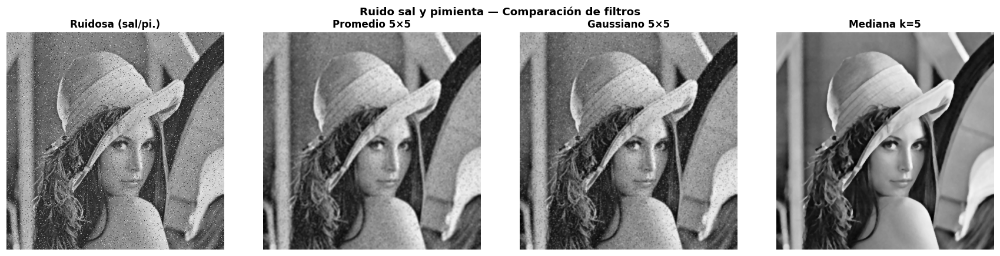


Error cuadrático medio (MSE) respecto a imagen sin ruido:
  Promedio 5×5        : MSE = 120.3
  Gaussiano 5×5       : MSE = 112.5
  Mediana k=5         : MSE = 51.9

💡 La mediana tiene el menor MSE ante ruido sal y pimienta.


In [6]:
# ══════════════════════════════════════════════════════════════════
# DEMO 1.3: Ruido sal y pimienta — ¿quién gana?
# ══════════════════════════════════════════════════════════════════

def add_salt_pepper(img, prob=0.05):
    """Agrega ruido sal y pimienta (prob = fracción de píxeles afectados)."""
    noisy = img.copy()
    total = img.size
    mask = np.random.choice([0, 1, 2],
                            size=img.shape,
                            p=[1-prob, prob/2, prob/2])
    noisy[mask == 1] = 0    # Pimienta (negro)
    noisy[mask == 2] = 255  # Sal (blanco)
    return noisy

def add_gaussian_noise(img, sigma=20):
    """Agrega ruido gaussiano."""
    ruido = np.random.normal(0, sigma, img.shape).astype(np.int16)
    noisy = np.clip(img.astype(np.int16) + ruido, 0, 255).astype(np.uint8)
    return noisy

# Crear versiones ruidosas
img_sp    = add_salt_pepper(img_gray, prob=0.05)   # 5% de píxeles
img_gauss_noise = add_gaussian_noise(img_gray, sigma=25)

# Aplicar filtros
results = {
    "Ruidosa (sal/pi.)": img_sp,
    "Promedio 5×5":      cv2.blur(img_sp, (5,5)),
    "Gaussiano 5×5":     cv2.GaussianBlur(img_sp, (5,5), 0),
    "Mediana k=5":       cv2.medianBlur(img_sp, 5),
}

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (title, img) in zip(axes, results.items()):
    ax.imshow(img, cmap='gray')
    ax.set_title(title)
    ax.axis('off')

plt.suptitle("Ruido sal y pimienta — Comparación de filtros", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# MSE (error cuadrático medio respecto a la original)
print("\nError cuadrático medio (MSE) respecto a imagen sin ruido:")
for name, img in list(results.items())[1:]:
    mse = np.mean((img.astype(float) - img_gray.astype(float))**2)
    print(f"  {name:20s}: MSE = {mse:.1f}")
print("\n💡 La mediana tiene el menor MSE ante ruido sal y pimienta.")

### ✏️ Ejercicio 1 — Tu turno

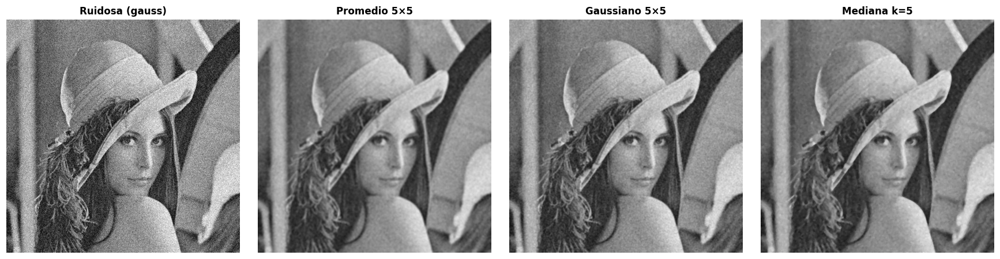

Ruidosa (gauss): MSE = 595.87
Promedio 5×5: MSE = 96.98
Gaussiano 5×5: MSE = 78.92
Mediana k=5: MSE = 96.43


In [7]:
# ══════════════════════════════════════════════════════════════════
# EJERCICIO 1: Probá con ruido gaussiano en lugar de sal y pimienta
# ══════════════════════════════════════════════════════════════════

# TODO: Aplicá los tres filtros sobre img_gauss_noise
# y comparalos visualmente usando plt.subplots

# img_gauss_noise ya está creada arriba

# Tu código aquí:
# Aplicar los tres filtros a la misma imagen con ruido gaussiano
results_gauss = {
    "Ruidosa (gauss)": img_gauss_noise,
    "Promedio 5×5": cv2.blur(img_gauss_noise, (5, 5)),
    "Gaussiano 5×5": cv2.GaussianBlur(img_gauss_noise, (5, 5), 0),
    "Mediana k=5": cv2.medianBlur(img_gauss_noise, 5),
}

# Mostrar los resultados
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (nombre, imagen) in zip(axes, results_gauss.items()):
    ax.imshow(imagen, cmap="gray", vmin=0, vmax=255)
    ax.set_title(nombre)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Comparar el error respecto a la imagen original
for nombre, imagen in results_gauss.items():
    mse = np.mean((imagen.astype(float) - img_gray.astype(float))**2)
    print(f"{nombre}: MSE = {mse:.2f}")

# R: En esta prueba, el filtro gaussiano obtuvo el menor MSE,
# reduciendo el ruido con menor error respecto a la original.
# Para sal y pimienta suele ser más adecuada la mediana,
# porque elimina los valores extremos blancos y negros.
# El gaussiano suaviza las variaciones de intensidad dando
# mayor peso a los píxeles cercanos.

---
## 🔷 Sección 2 — Detección de Bordes

### Repaso conceptual
```
Borde = región donde la intensidad cambia bruscamente
Gradiente (1ª derivada): Sobel, Prewitt → magnitud = √(Gx² + Gy²)
Segunda derivada:        Laplaciano → cruces por cero = bordes
Pipeline Canny:          Gaussiano → Sobel → NMS → Histéresis
```

### 🎬 Demo 2.1 — Gradiente manual (diferencias finitas)

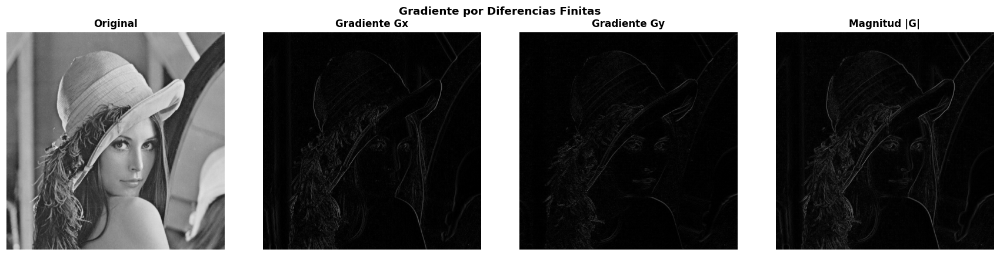

In [8]:
# ══════════════════════════════════════════════════════════════════
# DEMO 2.1: Gradiente manual con diferencias finitas
# ══════════════════════════════════════════════════════════════════

img_f = img_gray.astype(np.float32)

# Gradiente horizontal y vertical por diferencias finitas
Gx = np.zeros_like(img_f)
Gy = np.zeros_like(img_f)
Gx[:, 1:] = np.diff(img_f, axis=1)   # diferencia en X
Gy[1:, :] = np.diff(img_f, axis=0)   # diferencia en Y

# Magnitud del gradiente
magnitud = np.sqrt(Gx**2 + Gy**2)
magnitud = np.clip(magnitud, 0, 255).astype(np.uint8)

# Ángulo del gradiente
angulo = np.arctan2(Gy, Gx) * 180 / np.pi

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
datos = [
    (img_gray, "Original", 'gray'),
    (np.abs(Gx), "Gradiente Gx", 'gray'),
    (np.abs(Gy), "Gradiente Gy", 'gray'),
    (magnitud,   "Magnitud |G|", 'gray'),
]
for ax, (img, t, c) in zip(axes, datos):
    ax.imshow(img, cmap=c, vmin=0, vmax=255 if c=='gray' else None)
    ax.set_title(t)
    ax.axis('off')

plt.suptitle("Gradiente por Diferencias Finitas", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

### 🎬 Demo 2.2 — Operador Sobel con OpenCV

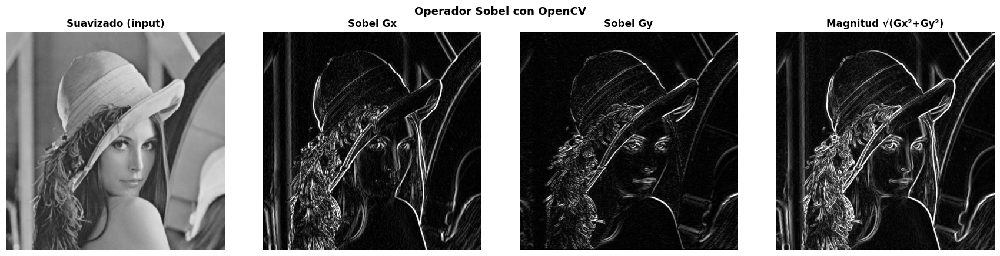

Rango magnitud Sobel: 0 – 255
Píxeles 'borde' (>30): 89936 de 262144


In [9]:
# ══════════════════════════════════════════════════════════════════
# DEMO 2.2: Sobel con OpenCV — comparación Gx, Gy, magnitud
# ══════════════════════════════════════════════════════════════════

# Preprocesamiento: suavizado gaussiano antes de Sobel
gray_smooth = cv2.GaussianBlur(img_gray, (3, 3), 0)

# Sobel en X (bordes verticales) y Y (bordes horizontales)
sobel_x = cv2.Sobel(gray_smooth, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gray_smooth, cv2.CV_64F, 0, 1, ksize=3)

# Magnitud
magnitud_sobel = cv2.magnitude(sobel_x.astype(np.float32),
                              sobel_y.astype(np.float32))
magnitud_sobel = np.clip(magnitud_sobel, 0, 255).astype(np.uint8)

# Dirección normalizada para visualizar
angulo_sobel = np.arctan2(np.abs(sobel_y), np.abs(sobel_x))
angulo_norm = (angulo_sobel / (np.pi / 2) * 255).astype(np.uint8)

# Limitar los valores a 0–255 antes de convertir para visualizar
sobel_x_visual = np.clip(np.abs(sobel_x), 0, 255).astype(np.uint8)
sobel_y_visual = np.clip(np.abs(sobel_y), 0, 255).astype(np.uint8)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, (img, t) in zip(axes, [
    (gray_smooth, "Suavizado (input)"),
    (sobel_x_visual, "Sobel Gx"),
    (sobel_y_visual, "Sobel Gy"),
    (magnitud_sobel, "Magnitud √(Gx²+Gy²)"),
]):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis('off')

plt.suptitle("Operador Sobel con OpenCV",
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Rango magnitud Sobel: {magnitud_sobel.min()} – {magnitud_sobel.max()}")
print(f"Píxeles 'borde' (>30): {(magnitud_sobel > 30).sum()} de {magnitud_sobel.size}")

### 🎬 Demo 2.3 — Canny: el estándar de la industria

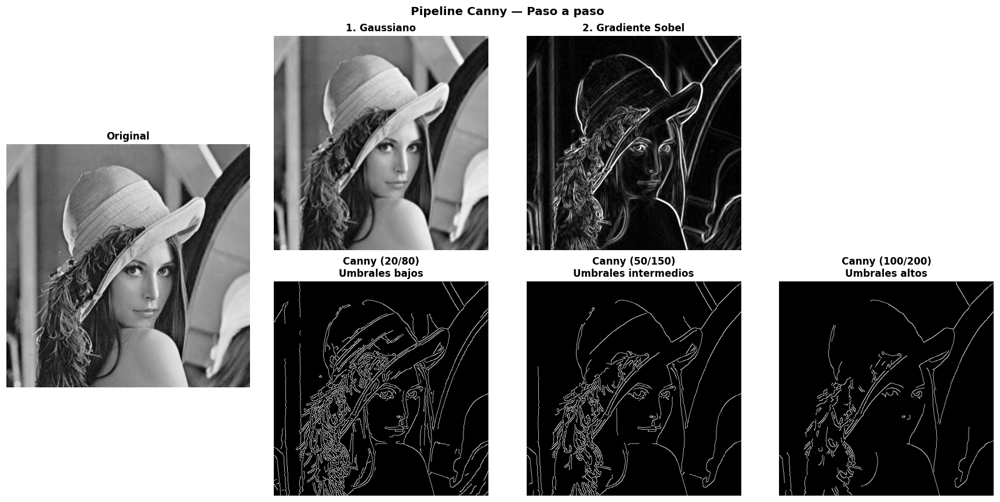

Canny (20/80): 7.43% de píxeles son borde
Canny (50/150): 4.59% de píxeles son borde
Canny (100/200): 2.72% de píxeles son borde


In [10]:
# ══════════════════════════════════════════════════════════════════
# DEMO 2.3: Canny — desglosamos sus 4 pasos
# ══════════════════════════════════════════════════════════════════

# Paso 1: Suavizado gaussiano antes de aplicar Canny
paso1 = cv2.GaussianBlur(img_gray, (5, 5), 1.4)

# Paso 2: Gradiente Sobel para mostrar esta etapa
Gx = cv2.Sobel(paso1, cv2.CV_64F, 1, 0, ksize=3)
Gy = cv2.Sobel(paso1, cv2.CV_64F, 0, 1, ksize=3)

paso2 = cv2.magnitude(Gx.astype(np.float32),
                      Gy.astype(np.float32))
paso2 = np.clip(paso2, 0, 255).astype(np.uint8)

# Canny calcula el gradiente, la supresión de no máximos
# y la histéresis sobre la imagen previamente suavizada.
canny_strict = cv2.Canny(paso1, 50, 150)
canny_loose = cv2.Canny(paso1, 20, 80)
canny_tight = cv2.Canny(paso1, 100, 200)

fig = plt.figure(figsize=(16, 8))
gs = gridspec.GridSpec(2, 4)

ax0 = fig.add_subplot(gs[:, 0])
ax0.imshow(img_gray, cmap='gray')
ax0.set_title("Original")
ax0.axis('off')

ax1 = fig.add_subplot(gs[0, 1])
ax1.imshow(paso1, cmap='gray')
ax1.set_title("1. Gaussiano")
ax1.axis('off')

ax2 = fig.add_subplot(gs[0, 2])
ax2.imshow(paso2, cmap='gray', vmin=0, vmax=255)
ax2.set_title("2. Gradiente Sobel")
ax2.axis('off')

ax3 = fig.add_subplot(gs[1, 1])
ax3.imshow(canny_loose, cmap='gray', vmin=0, vmax=255)
ax3.set_title("Canny (20/80)\nUmbrales bajos")
ax3.axis('off')

ax4 = fig.add_subplot(gs[1, 2])
ax4.imshow(canny_strict, cmap='gray', vmin=0, vmax=255)
ax4.set_title("Canny (50/150)\nUmbrales intermedios")
ax4.axis('off')

ax5 = fig.add_subplot(gs[1, 3])
ax5.imshow(canny_tight, cmap='gray', vmin=0, vmax=255)
ax5.set_title("Canny (100/200)\nUmbrales altos")
ax5.axis('off')

fig.suptitle("Pipeline Canny — Paso a paso",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Porcentaje de píxeles marcados como borde
for nombre, bordes in [
    ("20/80", canny_loose),
    ("50/150", canny_strict),
    ("100/200", canny_tight),
]:
    porcentaje = 100 * np.count_nonzero(bordes) / bordes.size
    print(f"Canny ({nombre}): {porcentaje:.2f}% de píxeles son borde")

### ✏️ Ejercicio 2 — Efecto del pre-suavizado en Canny

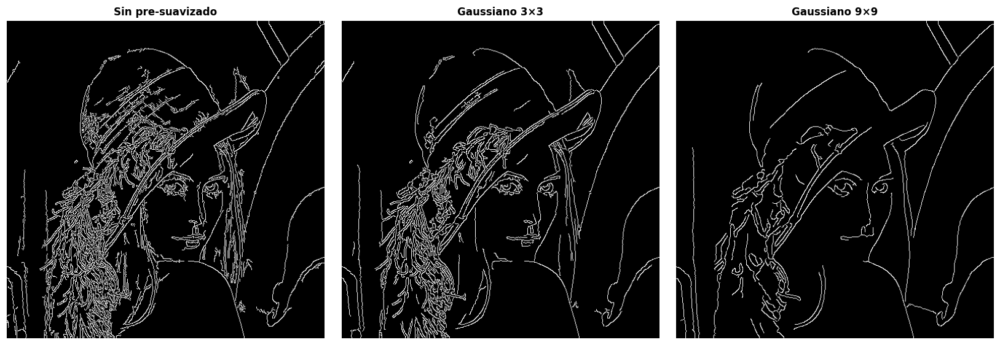

Sin pre-suavizado: 8.97% de píxeles son borde
Gaussiano 3×3: 6.51% de píxeles son borde
Gaussiano 9×9: 3.36% de píxeles son borde


In [11]:
# ══════════════════════════════════════════════════════════════════
# EJERCICIO 2: ¿El pre-suavizado afecta a Canny?
# ══════════════════════════════════════════════════════════════════

# El suavizado gaussiano se aplica explícitamente antes de Canny.
suave_3 = cv2.GaussianBlur(img_gray, (3, 3), 0)
suave_9 = cv2.GaussianBlur(img_gray, (9, 9), 0)

# Usar los mismos umbrales para comparar el efecto del suavizado
bordes_original = cv2.Canny(img_gray, 50, 150)
bordes_3 = cv2.Canny(suave_3, 50, 150)
bordes_9 = cv2.Canny(suave_9, 50, 150)

resultados = [
    ("Sin pre-suavizado", bordes_original),
    ("Gaussiano 3×3", bordes_3),
    ("Gaussiano 9×9", bordes_9),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, (nombre, bordes) in zip(axes, resultados):
    ax.imshow(bordes, cmap="gray", vmin=0, vmax=255)
    ax.set_title(nombre)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Comparar el porcentaje de píxeles detectados como borde
for nombre, bordes in resultados:
    porcentaje = 100 * np.count_nonzero(bordes) / bordes.size
    print(f"{nombre}: {porcentaje:.2f}% de píxeles son borde")

# R: El pre-suavizado fuerte reduce las variaciones pequeñas de
# intensidad, por lo que puede eliminar bordes débiles y detalles finos.
# Es útil cuando la imagen tiene ruido que genera bordes falsos.
# Sin embargo, un suavizado excesivo puede borrar contornos importantes.

---
## 🔷 Sección 3 — Transformada de Fourier (FFT)

### Concepto clave
```
Dominio espacial  → cada píxel = intensidad en esa posición
Dominio frecuencia → cada punto = amplitud de una onda sinusoidal

Centro del espectro = baja frecuencia (fondos uniformes)
Periferia           = alta frecuencia (bordes, texturas, ruido)
```

### 🎬 Demo 3.1 — Calcular y visualizar el espectro FFT

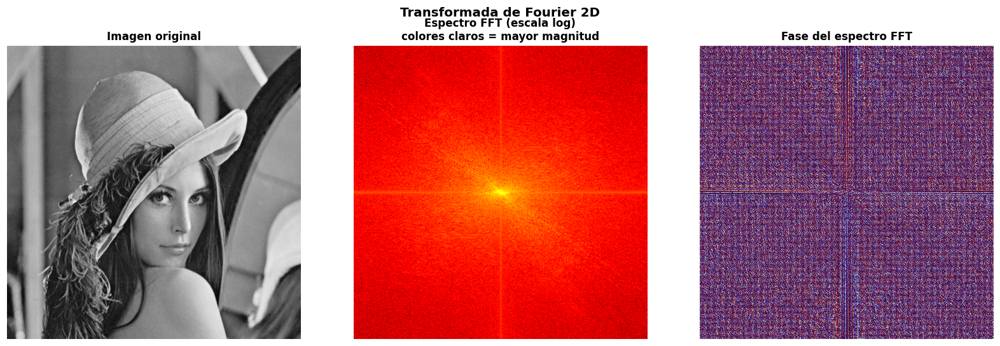

Imagen: 512×512 → FFT: 512×512 coeficientes complejos
Componente DC (F[0,0]): magnitud = 32558028.0


In [12]:
# ══════════════════════════════════════════════════════════════════
# DEMO 3.1: FFT 2D y su espectro de magnitud
# ══════════════════════════════════════════════════════════════════

# FFT 2D
fft2   = np.fft.fft2(img_gray)

# Centrar componente DC (frecuencia 0) al centro de la imagen
fft_shift = np.fft.fftshift(fft2)

# Espectro de magnitud (escala log para visualizar mejor)
magnitud_fft = np.abs(fft_shift)
espectro     = np.log1p(magnitud_fft)   # log1p = log(1 + x) evita log(0)

# Normalizar a [0, 255] para imshow
espectro_norm = cv2.normalize(espectro, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_gray, cmap='gray')
axes[0].set_title("Imagen original")
axes[0].axis('off')

axes[1].imshow(espectro_norm, cmap='hot')
axes[1].set_title("Espectro FFT (escala log)\ncolores claros = mayor magnitud")
axes[1].axis('off')

# Fase del espectro
fase = np.angle(fft_shift)
axes[2].imshow(fase, cmap='twilight')
axes[2].set_title("Fase del espectro FFT")
axes[2].axis('off')

plt.suptitle("Transformada de Fourier 2D", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

rows, cols = img_gray.shape
print(f"Imagen: {cols}×{rows} → FFT: {cols}×{rows} coeficientes complejos")
print(f"Componente DC (F[0,0]): magnitud = {magnitud_fft[rows//2, cols//2]:.1f}")

### 🎬 Demo 3.2 — Filtros en el dominio de la frecuencia

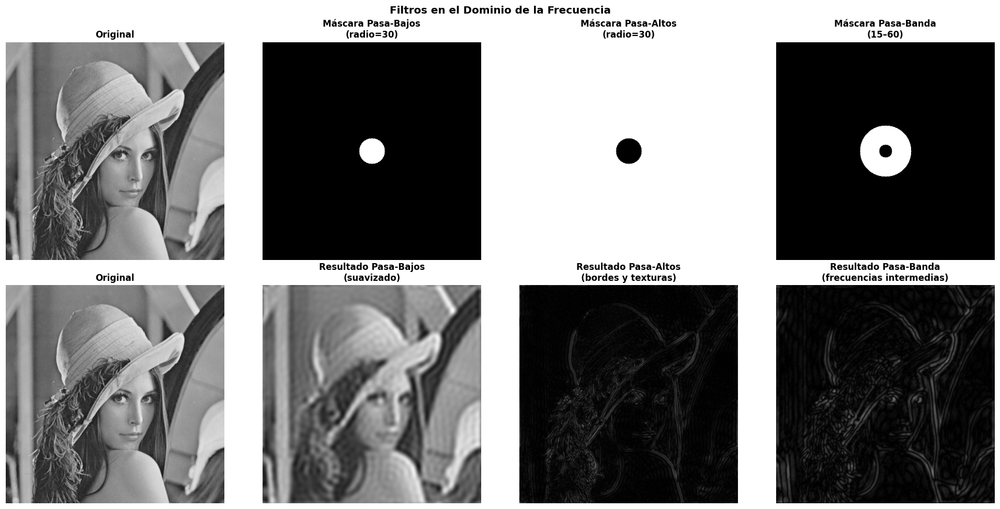

💡 El pasa-bajos suaviza al eliminar altas frecuencias.
   El pasa-altos resalta bordes, texturas y también ruido.
   El pasa-banda conserva un intervalo de frecuencias.
   El corte brusco de estas máscaras puede producir ondulaciones cerca de los bordes.


In [13]:
# ══════════════════════════════════════════════════════════════════
# DEMO 3.2: Filtros pasa-bajos, pasa-altos y pasa-banda
# ══════════════════════════════════════════════════════════════════

def make_circular_mask(shape, radius, inside=True):
    """Crea una máscara circular centrada en frecuencia cero."""
    rows, cols = shape
    cy, cx = rows // 2, cols // 2

    Y, X = np.ogrid[:rows, :cols]
    dist = np.sqrt((X - cx)**2 + (Y - cy)**2)

    mask = np.zeros(shape, dtype=np.float32)

    if inside:
        mask[dist <= radius] = 1    # Conserva bajas frecuencias
    else:
        mask[dist > radius] = 1     # Conserva altas frecuencias

    return mask


def apply_freq_filter(img, mask):
    """Aplica una máscara y reconstruye la imagen."""
    fft2 = np.fft.fft2(img)
    fft_shift = np.fft.fftshift(fft2)

    filtered = fft_shift * mask
    back = np.fft.ifftshift(filtered)
    result = np.fft.ifft2(back)

    # Conservar los valores reales, incluidos los negativos
    return np.real(result)


# Construir máscaras
rows, cols = img_gray.shape

mask_lp = make_circular_mask((rows, cols), radius=30, inside=True)
mask_hp = make_circular_mask((rows, cols), radius=30, inside=False)

mask_bp = (
    make_circular_mask((rows, cols), radius=60, inside=True)
    - make_circular_mask((rows, cols), radius=15, inside=True)
)

# Aplicar filtros
result_lp = apply_freq_filter(img_gray, mask_lp)
result_hp = apply_freq_filter(img_gray, mask_hp)
result_bp = apply_freq_filter(img_gray, mask_bp)

# Preparar resultados solo para visualización
visual_lp = np.clip(result_lp, 0, 255)
visual_hp = np.clip(np.abs(result_hp), 0, 255)
visual_bp = np.clip(np.abs(result_bp), 0, 255)

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for fila in range(2):
    axes[fila, 0].imshow(img_gray, cmap='gray', vmin=0, vmax=255)
    axes[fila, 0].set_title("Original")
    axes[fila, 0].axis('off')

titulos_masks = [
    "Máscara Pasa-Bajos\n(radio=30)",
    "Máscara Pasa-Altos\n(radio=30)",
    "Máscara Pasa-Banda\n(15–60)"
]

for ax, mask, titulo in zip(
    axes[0, 1:], [mask_lp, mask_hp, mask_bp], titulos_masks
):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=1)
    ax.set_title(titulo)
    ax.axis('off')

titulos_resultados = [
    "Resultado Pasa-Bajos\n(suavizado)",
    "Resultado Pasa-Altos\n(bordes y texturas)",
    "Resultado Pasa-Banda\n(frecuencias intermedias)"
]

for ax, res, titulo in zip(
    axes[1, 1:], [visual_lp, visual_hp, visual_bp], titulos_resultados
):
    ax.imshow(res, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis('off')

plt.suptitle("Filtros en el Dominio de la Frecuencia",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 El pasa-bajos suaviza al eliminar altas frecuencias.")
print("   El pasa-altos resalta bordes, texturas y también ruido.")
print("   El pasa-banda conserva un intervalo de frecuencias.")
print("   El corte brusco de estas máscaras puede producir ondulaciones cerca de los bordes.")

### ✏️ Ejercicio 3 — Diseñá tu propio filtro de frecuencia

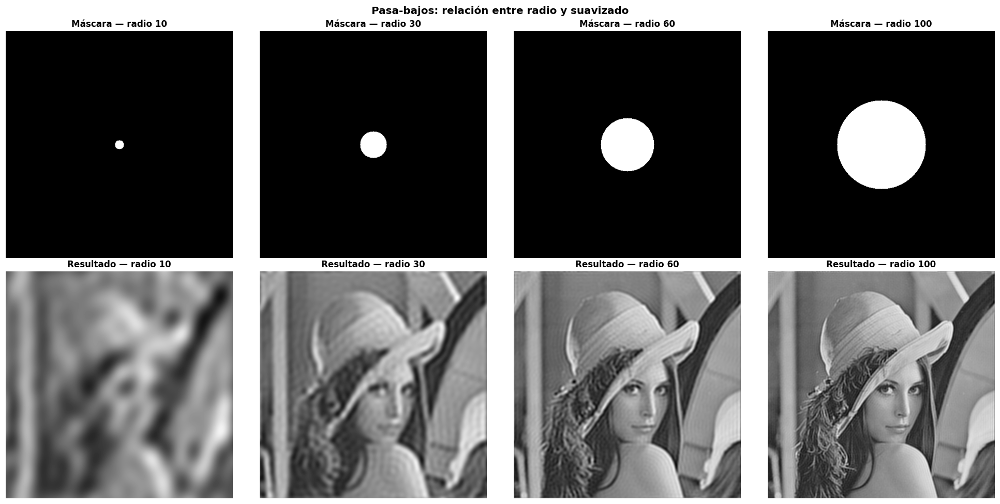

In [14]:
# ══════════════════════════════════════════════════════════════════
# EJERCICIO 3: Variá el radio del filtro pasa-bajos
# ══════════════════════════════════════════════════════════════════

radios = [10, 30, 60, 100]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

for i, r in enumerate(radios):
    mask = make_circular_mask(img_gray.shape, radius=r, inside=True)
    result = apply_freq_filter(img_gray, mask)

    axes[0, i].imshow(mask, cmap='gray', vmin=0, vmax=1)
    axes[0, i].set_title(f"Máscara — radio {r}")
    axes[0, i].axis('off')

    axes[1, i].imshow(np.clip(result, 0, 255),
                      cmap='gray', vmin=0, vmax=255)
    axes[1, i].set_title(f"Resultado — radio {r}")
    axes[1, i].axis('off')

plt.suptitle("Pasa-bajos: relación entre radio y suavizado",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Pregunta de análisis:
# ¿A qué radio el resultado pasa-bajos empieza a parecerse a la imagen original?
# ¿Qué información se pierde primero al bajar el radio?

# Respuesta:
# R: En esta imagen, con radio 60 el resultado empieza a parecerse
# claramente a la original, y con radio 100 la semejanza es mayor.
# Al bajar el radio se eliminan primero las altas frecuencias:
# detalles finos del cabello, texturas del sombrero y la nitidez
# de los bordes. Las formas generales se conservan por más tiempo.

### 🎬 Demo 3.3 — BONUS: FFT sobre imagen con patrón periódico

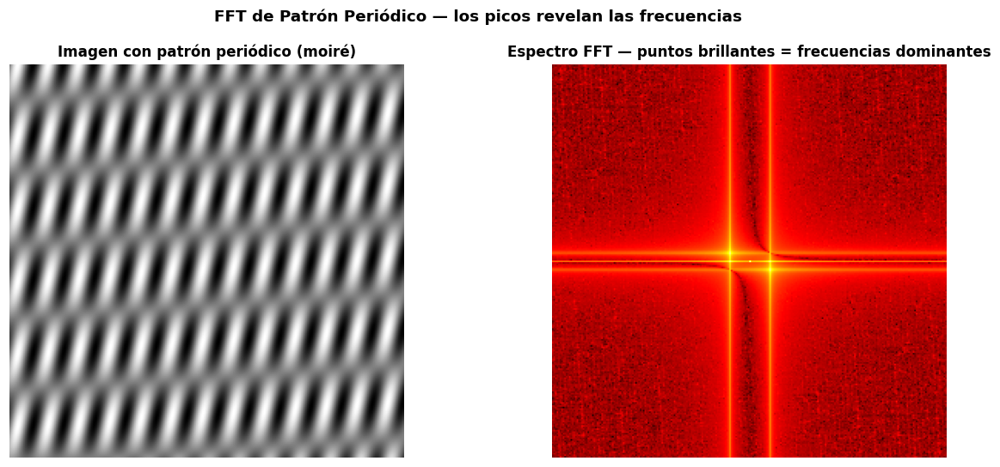

💡 En imágenes reales con interferencia moiré (scáner, pantalla fotografiada),
   estos picos en el espectro se pueden eliminar con una máscara puntual.


In [15]:
# ══════════════════════════════════════════════════════════════════
# DEMO 3.3 (BONUS): El espectro FFT de un patrón periódico
# La FFT es ideal para detectar y eliminar patrones repetitivos (ej: moiré)
# ══════════════════════════════════════════════════════════════════

# Crear imagen sintética con patrón periódico (interferencia moiré simulada)
rows, cols = 256, 256
Y, X = np.mgrid[:rows, :cols]

# Dos ondas senoidales que generan moiré
onda1 = np.sin(2 * np.pi * X / 20)   # frecuencia 1/20 píxeles
onda2 = np.sin(2 * np.pi * (X * np.cos(np.pi/8) + Y * np.sin(np.pi/8)) / 18)
img_patron = ((onda1 + onda2 + 2) / 4 * 255).astype(np.uint8)

# FFT del patrón
fft_patron    = np.fft.fft2(img_patron)
fft_sh        = np.fft.fftshift(fft_patron)
esp_patron    = np.log1p(np.abs(fft_sh))
esp_norm      = cv2.normalize(esp_patron, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(img_patron, cmap='gray')
axes[0].set_title("Imagen con patrón periódico (moiré)")
axes[0].axis('off')

axes[1].imshow(esp_norm, cmap='hot')
axes[1].set_title("Espectro FFT — puntos brillantes = frecuencias dominantes")
axes[1].axis('off')

plt.suptitle("FFT de Patrón Periódico — los picos revelan las frecuencias", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print("💡 En imágenes reales con interferencia moiré (scáner, pantalla fotografiada),")
print("   estos picos en el espectro se pueden eliminar con una máscara puntual.")

---
## 🔷 Sección 4 — Pipeline Integrado

Vamos a construir un pipeline realista que combine todos los conceptos de la semana:
**Ruido → Filtrado → Detección de bordes → Análisis de frecuencia**

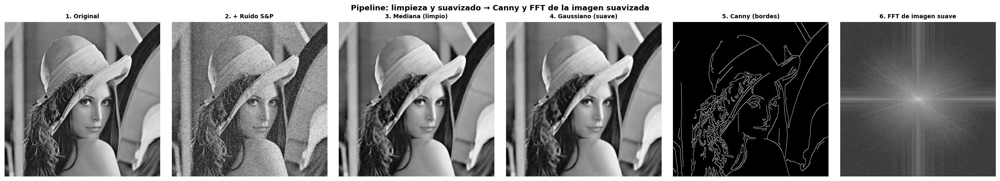

Pipeline ejecutado en 5 etapas:
  Etapa 1: 2. + Ruido S&P
  Etapa 2: 3. Mediana (limpio)
  Etapa 3: 4. Gaussiano (suave)
  Etapa 4: 5. Canny (bordes)
  Etapa 5: 6. FFT de imagen suave


In [16]:
# ══════════════════════════════════════════════════════════════════
# PIPELINE COMPLETO: Preprocesamiento → Bordes → FFT
# ══════════════════════════════════════════════════════════════════

# Etapa 1: Imagen con ruido sal y pimienta
imagen_ruidosa = add_salt_pepper(img_gray, prob=0.05)

# Etapa 2: Limpiar ruido con mediana
imagen_limpia = cv2.medianBlur(imagen_ruidosa, 5)

# Etapa 3: Suavizado fino con gaussiano para preparar bordes
imagen_suave = cv2.GaussianBlur(imagen_limpia, (3, 3), 0)

# Etapa 4: Detección de bordes Canny
bordes = cv2.Canny(imagen_suave, 40, 120)

# Etapa 5: Espectro FFT de la imagen suavizada
fft_final = np.fft.fft2(imagen_suave)
esp_final = np.log1p(np.abs(np.fft.fftshift(fft_final)))
esp_final_norm = cv2.normalize(
    esp_final, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

# Visualizar pipeline completo
etapas = [
    (img_gray,       "1. Original"),
    (imagen_ruidosa, "2. + Ruido S&P"),
    (imagen_limpia,  "3. Mediana (limpio)"),
    (imagen_suave,   "4. Gaussiano (suave)"),
    (bordes,         "5. Canny (bordes)"),
    (esp_final_norm, "6. FFT de imagen suave"),
]

fig, axes = plt.subplots(1, 6, figsize=(22, 4))

for ax, (img, t) in zip(axes, etapas):
    ax.imshow(img, cmap='gray')
    ax.set_title(t, fontsize=9)
    ax.axis('off')

plt.suptitle(
    "Pipeline: limpieza y suavizado → Canny y FFT de la imagen suavizada",
    fontsize=12, fontweight='bold'
)
plt.tight_layout()
plt.show()

print("Pipeline ejecutado en 5 etapas:")
for i, (_, t) in enumerate(etapas[1:], 1):
    print(f"  Etapa {i}: {t}")

### ✏️ Ejercicio Final — Pipeline propio

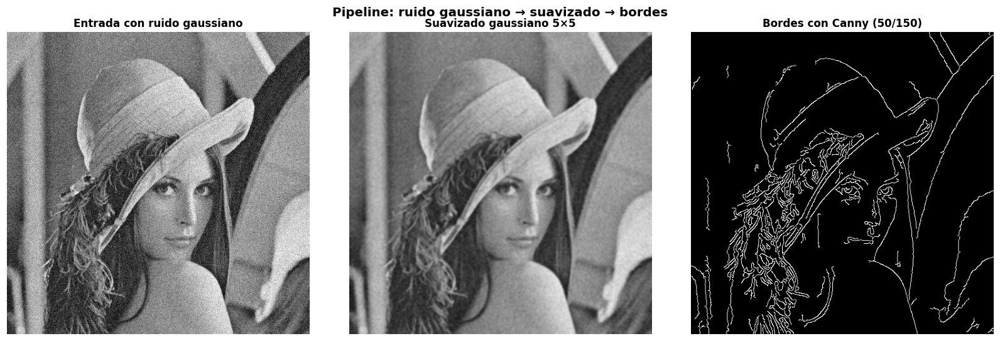

In [17]:
# ══════════════════════════════════════════════════════════════════
# EJERCICIO FINAL: Diseñá tu propio pipeline de preprocesamiento
# ══════════════════════════════════════════════════════════════════
#
# Escenario: recibís una imagen de rayos X con ruido gaussiano moderado.
# Necesitás entregar los bordes anatómicos más claros posible.
#
# Tu pipeline debe incluir al menos:
#   1. Agregar ruido gaussiano (sigma=20) con add_gaussian_noise()
#   2. Un paso de suavizado (elegí cuál y por qué)
#   3. Detección de bordes (Canny u otro)
#   4. Visualización comparando entrada vs. resultado
#
# Criterio de evaluación:
#   - Bordes claros y continuos ✓
#   - Mínimo ruido residual     ✓
#   - Justificación del filtro elegido en comentario ✓

# Tu código aquí:
# --------------

# 1. Agregar ruido gaussiano moderado
img_rx_ruidosa = add_gaussian_noise(img_gray, sigma=20)

# 2. Suavizado gaussiano para reducir el ruido
img_rx_limpia = cv2.GaussianBlur(img_rx_ruidosa, (5, 5), 1.4)

# 3. Detección de bordes
bordes_rx = cv2.Canny(img_rx_limpia, 50, 150)

# 4. Comparar entrada, imagen suavizada y bordes
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

imagenes = [img_rx_ruidosa, img_rx_limpia, bordes_rx]
titulos = [
    "Entrada con ruido gaussiano",
    "Suavizado gaussiano 5×5",
    "Bordes con Canny (50/150)"
]

for ax, img, titulo in zip(axes, imagenes, titulos):
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    ax.set_title(titulo)
    ax.axis('off')

plt.suptitle("Pipeline: ruido gaussiano → suavizado → bordes",
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Justificación del filtro elegido:
# R: Elegí el filtro gaussiano porque reduce el ruido gaussiano
# mediante un promedio ponderado de los píxeles vecinos.
# Usé un kernel 5×5 para reducir el ruido sin un suavizado excesivo.
# Luego apliqué Canny con umbrales 50 y 150 para conservar bordes
# fuertes y bordes débiles conectados a ellos, reduciendo respuestas
# aisladas causadas por el ruido.
# Un suavizado demasiado fuerte podría eliminar detalles importantes.

---
## 💬 Sección 5 — Actividad de Foro (Moodle)

### Consigna para el foro: "Filtros en el mundo real"

**Plazo:** 72 horas desde la publicación
**Modalidad:** 1 post original + 1 respuesta a un/a compañero/a

---

### 📝 Instrucciones

Buscá **una imagen real** (foto propia, descargada con licencia libre, o generada sintéticamente) donde la aplicación de alguna técnica de filtrado tenga sentido práctico.

**Tu post debe incluir:**

1. **Imagen original** (subila directamente al foro)
2. **Imagen procesada** con el filtro que elegiste
3. **3 líneas de código** que expliquen qué hiciste (no más)
4. **Respuesta a estas preguntas** (2-3 oraciones cada una):
   - ¿Qué problema tenía la imagen original?
   - ¿Por qué elegiste ese filtro (y no otro)?
   - ¿En qué aplicación real usarías esta técnica?

---

### 🎯 Ejemplos de aplicaciones posibles

| Área | Problema | Técnica sugerida |
|------|----------|-----------------|
| Medicina | Reducir ruido en imagen de ultrasonido | Filtro Gaussiano + Mediana |
| Agricultura | Detectar bordes de plantas en foto aérea | Canny con pre-suavizado |
| Seguridad | Resaltar bordes de objetos en video nocturno | Sobel + umbralización |
| Astronomía | Limpiar ruido térmico de imagen astronómica | Filtro Mediana k=3 |
| Manufactura | Detectar defectos en superficie metálica | FFT + pasa-banda |

---

### 📋 Celda de preparación (hacelo acá antes de subir al foro)

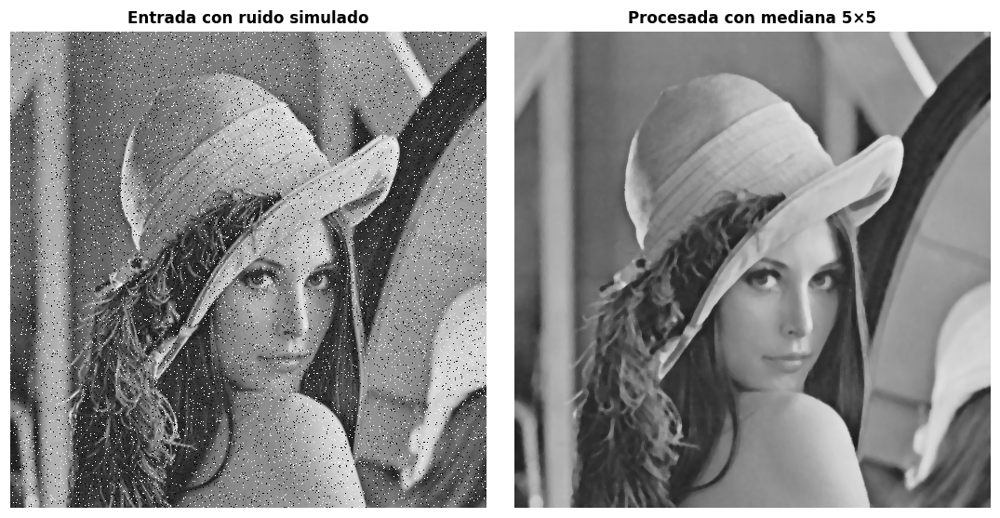

Imágenes guardadas:
  foro_original.png — entrada con ruido simulado
  foro_procesada.png — resultado del filtro
  mi_post_foro.png — comparación de ambas


In [18]:
# ══════════════════════════════════════════════════════════════════
# PREPARACIÓN FORO: Generá acá la imagen para tu post
# ══════════════════════════════════════════════════════════════════

# Opción A: usá img_gray (Lena) como base
# Opción B: subí tu propia imagen con:
#   from google.colab import files
#   uploaded = files.upload()
#   img_mia = cv2.imread(list(uploaded.keys())[0], cv2.IMREAD_GRAYSCALE)

# TODO: Completá el pipeline para tu imagen del foro

# ══════════════════════════════════════════════════════════════════
# PREPARACIÓN FORO: Reducción de ruido sal y pimienta
# ══════════════════════════════════════════════════════════════════

# Las 3 líneas de procesamiento para incluir en el post:
img_base = img_gray.copy()
img_foro = add_salt_pepper(img_base, prob=0.05)
resultado_foro = cv2.medianBlur(img_foro, 5)

# Visualización
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.imshow(img_foro, cmap='gray', vmin=0, vmax=255)
ax1.set_title("Entrada con ruido simulado")
ax1.axis('off')

ax2.imshow(resultado_foro, cmap='gray', vmin=0, vmax=255)
ax2.set_title("Procesada con mediana 5×5")
ax2.axis('off')

plt.tight_layout()
plt.savefig("mi_post_foro.png", dpi=150, bbox_inches='tight')
plt.show()

# Guardar las dos imágenes por separado para subir al foro
cv2.imwrite("foro_original.png", img_foro)
cv2.imwrite("foro_procesada.png", resultado_foro)

print("Imágenes guardadas:")
print("  foro_original.png — entrada con ruido simulado")
print("  foro_procesada.png — resultado del filtro")
print("  mi_post_foro.png — comparación de ambas")

### Análisis del filtrado

**¿Qué problema tenía la imagen original?**

Agregué ruido sal y pimienta simulado a la imagen de Lena para representar una imagen deteriorada. Los puntos blancos y negros dificultaban la observación de sus detalles.

**¿Por qué elegiste ese filtro y no otro?**

Elegí el filtro de mediana 5×5 porque reduce eficazmente los valores extremos del ruido sal y pimienta. A diferencia del promedio y del gaussiano, evita que esos valores extremos se distribuyan entre los píxeles vecinos, aunque también suaviza algunas texturas finas.

**¿En qué aplicación real usarías esta técnica?**

Usaría esta técnica para limpiar fotografías digitalizadas que presenten puntos blancos y negros aislados. Podría aplicarse antes de detectar bordes para reducir las detecciones falsas causadas por ese ruido.

---
## 📊 Resumen de la Clase 8

### ¿Qué aprendimos hoy?

| Técnica | Cuándo usar | Parámetros clave |
|---------|-------------|-----------------|
| **cv2.blur()** | Ruido uniforme leve, velocidad importa | ksize: tamaño del kernel |
| **cv2.GaussianBlur()** | Antes de Canny/Sobel, preprocesado general | ksize (impar), sigma |
| **cv2.medianBlur()** | Ruido sal y pimienta | ksize (impar) |
| **cv2.Sobel()** | Gradiente en X o Y, análisis de orientación | dx, dy, ksize |
| **cv2.Canny()** | Detección de bordes completa, producción | threshold1, threshold2 |
| **np.fft.fft2()** | Análisis de frecuencia, filtros periódicos | — |

### Regla práctica
```
Ruido sal/pimienta  → Mediana
Ruido gaussiano     → Gaussiano
Bordes rápidos      → Sobel
Bordes de calidad   → Canny (con GaussianBlur previo)
Patrones repetidos  → FFT + máscara en frecuencia
```

---
## 🚀 Semana 5 — Adelanto

En la próxima semana vamos a ver **Redes Neuronales Convolucionales (CNNs)**:
- Cómo una CNN *aprende* los filtros que hoy aplicamos manualmente
- Arquitectura: Conv → ReLU → Pooling → FC → Softmax
- Transfer Learning con modelos preentrenados (VGG, ResNet, MobileNet)
- Clasificación de imágenes con TensorFlow/Keras

> 💡 Lo que hiciste hoy manualmente (Sobel, Gaussiano) la CNN lo aprende automáticamente
> a partir de los datos — eso es la magia del deep learning en imágenes.

In [19]:
# ══════════════════════════════════════════════════════════════════
# VERIFICACIÓN FINAL — Chequeo de ejercicios completados
# ══════════════════════════════════════════════════════════════════

ejercicios = {
    "Ejercicio 1 — Filtros con ruido gaussiano": True,
    "Ejercicio 2 — Pre-suavizado en Canny": True,
    "Ejercicio 3 — Variación de radio FFT": True,
    "Ejercicio Final — Pipeline propio": True,
    "Actividad Foro — Imagen preparada": True,
}

print("=" * 50)
print("  CHECKLIST — Clase 8: Filtrado y Frecuencia")
print("=" * 50)

completados = 0
for nombre, hecho in ejercicios.items():
    estado = "✅" if hecho else "⬜"
    print(f"  {estado}  {nombre}")
    if hecho:
        completados += 1

print("=" * 50)
print(f"  Completados: {completados}/{len(ejercicios)}")

if completados == len(ejercicios):
    print("  🎉 ¡Laboratorio completado!")
else:
    print(f"  ⚠️  Faltan {len(ejercicios)-completados} ejercicios")

print("=" * 50)

  CHECKLIST — Clase 8: Filtrado y Frecuencia
  ✅  Ejercicio 1 — Filtros con ruido gaussiano
  ✅  Ejercicio 2 — Pre-suavizado en Canny
  ✅  Ejercicio 3 — Variación de radio FFT
  ✅  Ejercicio Final — Pipeline propio
  ✅  Actividad Foro — Imagen preparada
  Completados: 5/5
  🎉 ¡Laboratorio completado!
